In [1]:
from typing import List, Tuple
import datetime as dt

METADATA_AND_DATA_FILENAMES_CONTAINING_DATE_FILENAME = 'meta_and_data_filenames_on_remote_volume.txt'

def convert_cygnss_name_to_norad_name(cygnss_name:str)->str:
    '''
    The CYGNSS satellites are named cyg01, cyg02, ..., cyg08.
    This converts them on to the cygfm01, cygfm02, ..., cygfm08 format.
    '''
    return 'cygfm' + cygnss_name[3:]

# Should contain tuples on the form (CYGNSS Satellite NORAD ID, (Start Date, End Date))
# The dates should be in datetime.datetime
date_and_satellite_list: List[Tuple[str, Tuple[dt.datetime, dt.datetime]]] = []
with open(METADATA_AND_DATA_FILENAMES_CONTAINING_DATE_FILENAME, 'r') as file:
    '''
    The format of the lines are:
    cyg01_raw_if_s20170909_062000_e20170909_062100_data.bin
    cyg01_raw_if_s20170909_062000_e20170909_062100_meta.bin
    ...

    There is one data and one metafile for satellite and time range.
    '''
    date_and_sat_set = set() 
    for line in file:
        if 'meta' in line:
            continue
        columns = line.split('_')
        satellite = columns[0]
        start_date = columns[4]
        end_date = columns[6]

        cygnss_id = columns[0]             # Extract ID
        start_time_string = columns[3][1:] + columns[4] # Extract start time. The [1:] is to remove the 's' in the string
        end_time_string   = columns[5][1:] + columns[6] # Extract end time. The [1:] is to remove the 'e' in the string

        start_time = dt.datetime.strptime(start_time_string, '%Y%m%d%H%M%S')
        end_time = dt.datetime.strptime(end_time_string, '%Y%m%d%H%M%S')
        date_and_sat_set.add((convert_cygnss_name_to_norad_name(cygnss_id), (start_time, end_time)))

    print(f"Length of the set: {len(date_and_sat_set)}")
    date_and_satellite_list = list(date_and_sat_set)
    print(date_and_satellite_list)
        


Length of the set: 493
[('cygfm08', (datetime.datetime(2022, 4, 10, 18, 31, 33), datetime.datetime(2022, 4, 10, 18, 32, 4))), ('cygfm02', (datetime.datetime(2022, 10, 8, 5, 52, 52), datetime.datetime(2022, 10, 8, 5, 53, 52))), ('cygfm07', (datetime.datetime(2021, 7, 20, 21, 11, 46), datetime.datetime(2021, 7, 20, 21, 12, 46))), ('cygfm07', (datetime.datetime(2023, 3, 6, 1, 37, 27), datetime.datetime(2023, 3, 6, 1, 38, 27))), ('cygfm01', (datetime.datetime(2018, 3, 30, 15, 57), datetime.datetime(2018, 3, 30, 15, 58))), ('cygfm04', (datetime.datetime(2022, 5, 12, 2, 47, 14), datetime.datetime(2022, 5, 12, 2, 48, 15))), ('cygfm07', (datetime.datetime(2020, 6, 21, 6, 51, 9), datetime.datetime(2020, 6, 21, 6, 52, 9))), ('cygfm08', (datetime.datetime(2023, 9, 3, 11, 7, 20), datetime.datetime(2023, 9, 3, 11, 8, 21))), ('cygfm07', (datetime.datetime(2017, 9, 21, 15, 39, 40), datetime.datetime(2017, 9, 21, 15, 40, 40))), ('cygfm06', (datetime.datetime(2022, 3, 4, 15, 14, 31), datetime.datetime(

In [2]:
import spacetrack.operators as op
from spacetrack import SpaceTrackClient
import re
import json
import numpy as np
from skyfield.api import load
from functions.functions import compute_reflection
from mpl_toolkits.basemap import Basemap
import matplotlib.pyplot as plt
import pymap3d
import os
from dotenv import load_dotenv
import satellite_parameter_utils as utils

def does_track_cross_from_land_to_sea(basemap, track: np.array) -> bool:
    previous_point = None
    for evaluation_point in track:
        if not previous_point: # Handle the first point
            if Basemap.is_land(basemap, evaluation_point[0], evaluation_point[1]):
                previous_point = "land"
            else:
                previous_point = "sea"
            continue
        if Basemap.is_land(basemap, evaluation_point[0], evaluation_point[1]):
            if previous_point == "sea":
                return True
            previous_point = "land"
        else:
            if previous_point == "land":
                return True
            previous_point = "sea"
    return False


Processing cygfm08 from 2022-04-10 18:31:33 to 2022-04-10 18:32:04
Processing cygfm02 from 2022-10-08 05:52:52 to 2022-10-08 05:53:52
Processing cygfm07 from 2021-07-20 21:11:46 to 2021-07-20 21:12:46
Processing cygfm07 from 2023-03-06 01:37:27 to 2023-03-06 01:38:27
Already processed cygfm07 from 2023-03-06 01:37:27 to 2023-03-06 01:38:27
Processing cygfm01 from 2018-03-30 15:57:00 to 2018-03-30 15:58:00
Already processed cygfm01 from 2018-03-30 15:57:00 to 2018-03-30 15:58:00
Processing cygfm04 from 2022-05-12 02:47:14 to 2022-05-12 02:48:15
Processing cygfm07 from 2020-06-21 06:51:09 to 2020-06-21 06:52:09
Processing cygfm08 from 2023-09-03 11:07:20 to 2023-09-03 11:08:21
Processing cygfm07 from 2017-09-21 15:39:40 to 2017-09-21 15:40:40
Processing cygfm06 from 2022-03-04 15:14:31 to 2022-03-04 15:15:32
Processing cygfm03 from 2022-05-07 08:19:05 to 2022-05-07 08:20:06
Already processed cygfm03 from 2022-05-07 08:19:05 to 2022-05-07 08:20:06
Processing cygfm05 from 2024-02-17 21:00:

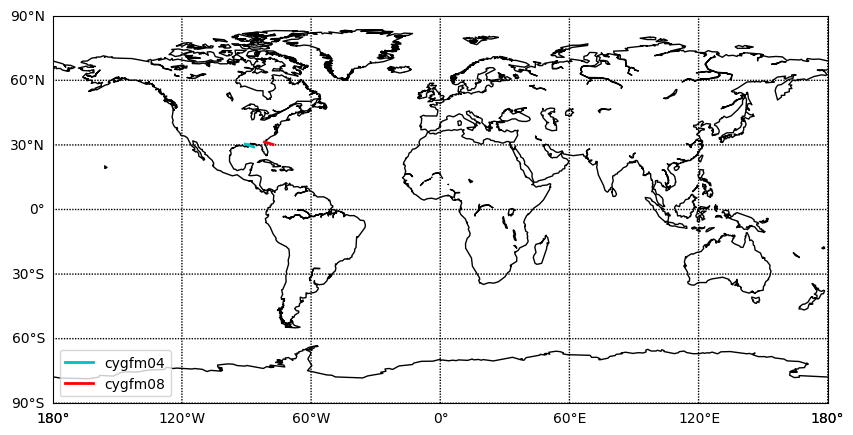

In [ ]:


##################################################################
############################# INPUT ##############################
##################################################################

NUM_SATS_TO_LOOK_AT = 30  # Limit number of satellites for testing

# Retrieve access to TLEs from SpaceTrack
dotenv_path = os.path.join(os.path.dirname(os.getcwd()), '.env')
load_dotenv(dotenv_path)

spacetrack_username = os.getenv("SPACETRACK_ID")
spacetrack_password = os.getenv("SPACETRACK_PASS")

# SpaceTrack client
st = SpaceTrackClient(identity=spacetrack_username, password=spacetrack_password)

##################################################################
#################### Create CYGNSS TLE file ######################
##################################################################

# # Limit processing if NUM_SATS_TO_LOOK_AT is set
# if NUM_SATS_TO_LOOK_AT is not None:
#     date_and_satellite_list = date_and_satellite_list[:NUM_SATS_TO_LOOK_AT]

# Prepare Basemap figure
plt.figure(figsize=(10, 10))
earth_visualization_map = Basemap(projection='cyl', llcrnrlat=-90, urcrnrlat=90,
                                  llcrnrlon=-180, urcrnrlon=180, resolution='c')

earth_visualization_map.drawcoastlines()
parallels = range(-90, 91, 30)   # Latitude lines every 30 degrees
meridians = range(-180, 181, 60)  # Longitude lines every 60 degrees
earth_visualization_map.drawparallels(parallels, labels=[1, 0, 0, 0], fontsize=10)
earth_visualization_map.drawmeridians(meridians, labels=[0, 0, 0, 1], fontsize=10)

# Color options for multiple tracks
color_vector = ['r', 'g', 'b', 'y', 'm', 'c', 'k']

# Load timescale
ts = load.timescale()


'''
Format of the json file should be:
{
    "cygfm01": [
        {
            "date_start": "2017-09-09 06:20:00",
            "date_end": "2017-09-09 06:21:00",
            "track": [[lon1, lat1], [lon2, lat2], ...]
        },
        {
            "date_start": "2018-08-27 00:34:43",
            "date_end": "2018-08-27 00:35:43",
            "track": []
        }
    ],
    "cygfm02": [
        {
            "date_start": "2017-09-21 15:41:15",
            "date_end": "2017-09-21 15:42:15",
            "track": [[lon1, lat1], [lon2, lat2], ...]
        }
    ]
}
'''
ALREADY_PROCESSED_SATELLITES_AND_DATES_FILENAME = 'already_processed_satellites_and_dates.json'
already_processed_satellites_and_dates = {}
if os.path.exists(ALREADY_PROCESSED_SATELLITES_AND_DATES_FILENAME):
    with open(ALREADY_PROCESSED_SATELLITES_AND_DATES_FILENAME, 'r') as file:
        already_processed_satellites_and_dates = json.load(file)
else:
    already_processed_satellites_and_dates = {}

processed_satellite_counter = 0
for idx, (cygnss_satellite_name, (date_start, date_end)) in enumerate(date_and_satellite_list):
    # Check if the satellite and date has already been processed. Wildly inefficient check.
    if cygnss_satellite_name in already_processed_satellites_and_dates:
        processed_dates = {(entry["date_start"], entry["date_end"]) for entry in already_processed_satellites_and_dates[cygnss_satellite_name]}
        if (str(date_start), str(date_end)) in processed_dates:
            print(f"Already processed {cygnss_satellite_name} from {date_start} to {date_end}")
            continue
    print(f"Processing {cygnss_satellite_name} from {date_start} to {date_end}")
    
    if processed_satellite_counter >= NUM_SATS_TO_LOOK_AT:
        print(f"Processed {processed_satellite_counter} satellites. Stopping.")
        break
    processed_satellite_counter += 1


    # Retrieve CYGNSS TLE
    cygnss_satellite_tle_data_json = st.satcat(satname=cygnss_satellite_name, format='json')

    # If TLE data exists, process it
    if cygnss_satellite_tle_data_json:
        cygnss_satellite_data = json.loads(cygnss_satellite_tle_data_json)
        norad_cat_id_cy = cygnss_satellite_data[0].get("NORAD_CAT_ID")

        # Fetch latest TLEs
        date_search_range = op.inclusive_range(date_start.date(), date_end.date() + dt.timedelta(days=1))
        lines = list(st.tle(iter_lines=True, norad_cat_id=norad_cat_id_cy, epoch=date_search_range, orderby="EPOCH", format="tle"))

        # Save to file
        tle_filepath = f"../TLE_EPHEMIRIS_files/cygnss_TLE_{cygnss_satellite_name}.txt"
        with open(tle_filepath, "w") as file:
            if lines:
                last_elements = lines[-2:]
                file.write(f"NORAD ID: {norad_cat_id_cy}\n")
                for line in last_elements:
                    file.write(line.strip() + "\n")
            else:
                print(f"No TLE data found for {cygnss_satellite_name}.")
                continue

        # Load CYGNSS satellite TLE
        satellites_LEO_sk = load.tle_file(tle_filepath)
        satellite_leo = satellites_LEO_sk[0]

        # Generate time series
        step = 1  # Time step in seconds
        seconds_array = np.arange(0, (date_end - date_start).total_seconds(), step)
        times_1 = ts.utc(date_start.year, date_start.month, date_start.day,
                         date_start.hour, date_start.minute, date_start.second + seconds_array)

        # Get satellite positions
        position = np.array([satellite_leo.at(t).position.m for t in times_1])
        position = np.transpose(position)

        # Convert ECI to geodetic coordinates
        lat, lon, alt = pymap3d.eci2geodetic(position[0, :], position[1, :], position[2, :], [t.utc_datetime() for t in times_1])
        
        # Check if track crosses from land to sea or vice versa
        track_crosses_from_land_to_sea = does_track_cross_from_land_to_sea(earth_visualization_map, np.array([lon, lat]).T)

        # Save track to json file. Retain the name of the satellite, date, and track IF it crosses from land to sea.
        # we want to keep track of these already processed satellites to not have to process them again.
        processed_entry = {
            "date_start": str(date_start),
            "date_end": str(date_end),
            "track": np.array([lon, lat]).T.tolist() if track_crosses_from_land_to_sea else None
        }
        # Append to already processed satellites and dates

        if cygnss_satellite_name not in already_processed_satellites_and_dates:
            already_processed_satellites_and_dates[cygnss_satellite_name] = []

        already_processed_satellites_and_dates[cygnss_satellite_name].append(processed_entry)
    


        # Plot CYGNSS track if it crosses from land to sea
        if track_crosses_from_land_to_sea:
            print(f"Plotting {cygnss_satellite_name} from {date_start} to {date_end}")
            earth_visualization_map.plot(lon, lat, linewidth=2, color=color_vector[idx % len(color_vector)],
                                         label=f"{cygnss_satellite_name}")
            
with open(ALREADY_PROCESSED_SATELLITES_AND_DATES_FILENAME, 'w') as file:
    json.dump(already_processed_satellites_and_dates, file, indent=4)

# Add legend and show the plot
plt.legend(loc='lower left')
plt.xticks(fontsize=12)
plt.show()